MAE: 0.248 seconds
R²: 0.939


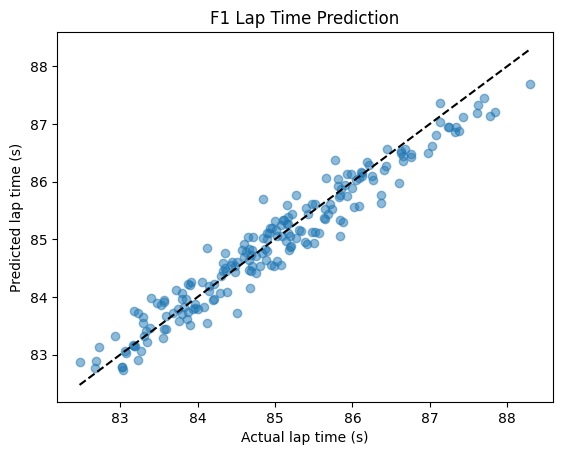

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Generating vehicle performance data
rng = np.random.default_rng(42)
n = 1000

data = pd.DataFrame({
    "tyre_age": rng.integers(1, 35, n),
    "track_temp": rng.uniform(20, 50, n),
    "fuel_load": rng.uniform(5, 100, n),
    "downforce": rng.uniform(0.8, 1.2, n),
})

# Simplified lap-time relationship
data["lap_time"] = (
    85
    + 0.06 * data["tyre_age"]
    + 0.025 * (data["track_temp"] - 30)
    + 0.035 * data["fuel_load"]
    - 3.0 * data["downforce"]
    + rng.normal(0, 0.25, n)
)

# Separating features and target
X = data.drop(columns=["lap_time"])
y = data["lap_time"]

# Splitting into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Training a machine-learning model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)

# Evaluating predictions on unseen data
predictions = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, predictions), 3), "seconds")
print("R²:", round(r2_score(y_test, predictions), 3))

# Visualising predictions
plt.scatter(y_test, predictions, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "k--"
)
plt.xlabel("Actual lap time (s)")
plt.ylabel("Predicted lap time (s)")
plt.title("F1 Lap Time Prediction")
plt.show()


fuel_load     0.646375
tyre_age      0.220549
downforce     0.095488
track_temp    0.037588
dtype: float64


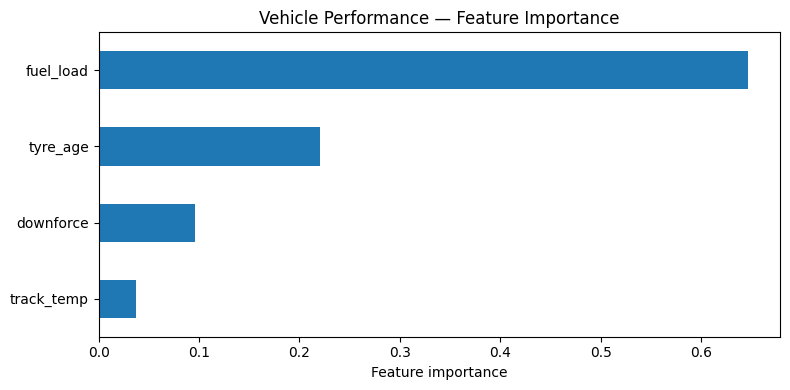

In [14]:

importances = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importances)

importances.sort_values().plot(
    kind="barh",
    figsize=(8, 4)
)

plt.xlabel("Feature importance")
plt.title("Vehicle Performance — Feature Importance")
plt.tight_layout()
plt.show()


In [15]:

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE (seconds)": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, predictions)
    ],
    "R²": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, predictions)
    ]
})

print(comparison.round(3))


               Model  MAE (seconds)     R²
0  Linear Regression          0.207  0.959
1      Random Forest          0.248  0.939


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.default_rng(42)
n = 3000

data_v2 = pd.DataFrame({
    "tyre_age": rng.uniform(0, 40, n),
    "track_temp": rng.uniform(20, 55, n),
    "fuel_load": rng.uniform(5, 100, n),
    "downforce": rng.uniform(0.8, 1.2, n)
})

# Nonlinear tyre degradation
tyre_degradation = 0.003 * data_v2["tyre_age"]**2

# Temperature and tyre-age interaction
temperature_effect = (
    0.002 * (data_v2["track_temp"] - 35)**2
    + 0.0015 * data_v2["tyre_age"]
    * np.maximum(data_v2["track_temp"] - 35, 0)
)

# Illustrative lap-time model
data_v2["lap_time"] = (
    85
    + tyre_degradation
    + temperature_effect
    + 0.035 * data_v2["fuel_load"]
    - 3.0 * data_v2["downforce"]
    + rng.normal(0, 0.25, n)
)

X2 = data_v2.drop(columns=["lap_time"])
y2 = data_v2["lap_time"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

print(data_v2.head())


    tyre_age  track_temp  fuel_load  downforce   lap_time
0  30.958242   49.022740  48.270256   1.149463  87.230422
1  17.555138   40.793360  16.291509   0.898423  83.716288
2  34.343917   28.569916  59.071476   0.995586  87.600700
3  27.894721   46.098625  19.860739   0.811887  86.145037
4   3.767094   22.956831  10.791042   0.803552  83.053185


In [17]:

linear_v2 = LinearRegression()
forest_v2 = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

linear_v2.fit(X2_train, y2_train)
forest_v2.fit(X2_train, y2_train)

pred_linear = linear_v2.predict(X2_test)
pred_forest = forest_v2.predict(X2_test)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE (s)": [
        mean_absolute_error(y2_test, pred_linear),
        mean_absolute_error(y2_test, pred_forest)
    ],
    "R2": [
        r2_score(y2_test, pred_linear),
        r2_score(y2_test, pred_forest)
    ]
})

print(results.round(4))

               Model  MAE (s)      R2
0  Linear Regression   0.4198  0.9230
1      Random Forest   0.2542  0.9696


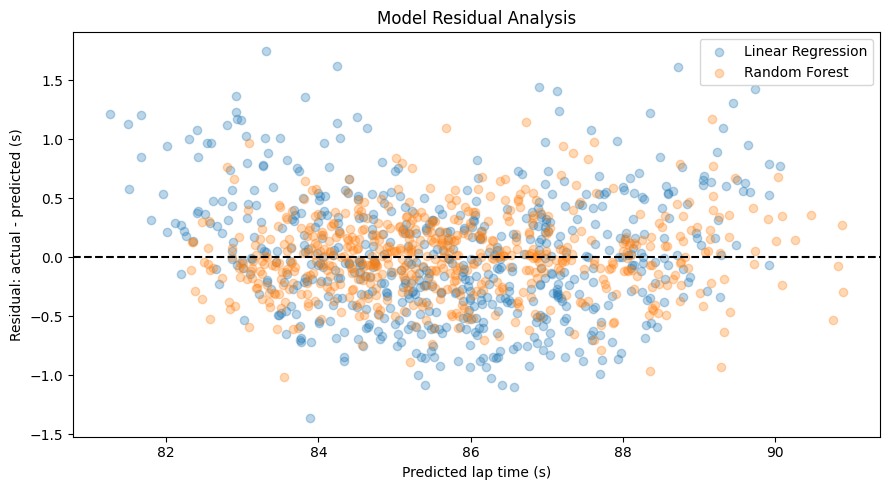

In [18]:
residuals_linear = y2_test - pred_linear
residuals_forest = y2_test - pred_forest

plt.figure(figsize=(9, 5))

plt.scatter(
    pred_linear,
    residuals_linear,
    alpha=0.3,
    label="Linear Regression"
)

plt.scatter(
    pred_forest,
    residuals_forest,
    alpha=0.3,
    label="Random Forest"
)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Predicted lap time (s)")
plt.ylabel("Residual: actual - predicted (s)")
plt.title("Model Residual Analysis")
plt.legend()
plt.tight_layout()
plt.show()


In [19]:

challenging = X2_test[
    (X2_test["tyre_age"] > 30)
    & (X2_test["track_temp"] > 40)
]

if len(challenging) > 0:
    actual = y2_test.loc[challenging.index]

    print("Challenging test samples:", len(challenging))

    print(
        "Linear Regression MAE:",
        round(mean_absolute_error(
            actual,
            linear_v2.predict(challenging)
        ), 4)
    )

    print(
        "Random Forest MAE:",
        round(mean_absolute_error(
            actual,
            forest_v2.predict(challenging)
        ), 4)
    )
else:
    print("No matching test samples.")


Challenging test samples: 61
Linear Regression MAE: 0.548
Random Forest MAE: 0.312


In [20]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

polynomial_v2 = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1.0)
)

polynomial_v2.fit(X2_train, y2_train)

pred_poly = polynomial_v2.predict(X2_test)

comparison_v3 = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Polynomial Regression"
    ],
    "MAE (s)": [
        mean_absolute_error(y2_test, pred_linear),
        mean_absolute_error(y2_test, pred_forest),
        mean_absolute_error(y2_test, pred_poly)
    ],
    "R2": [
        r2_score(y2_test, pred_linear),
        r2_score(y2_test, pred_forest),
        r2_score(y2_test, pred_poly)
    ]
})

print(comparison_v3.round(4))


                   Model  MAE (s)      R2
0      Linear Regression   0.4198  0.9230
1          Random Forest   0.2542  0.9696
2  Polynomial Regression   0.1970  0.9827


In [21]:

from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        Ridge(alpha=1.0)
    )
}

cv_results = []

for name, estimator in models.items():
    scores = -cross_val_score(
        estimator,
        X2_train,
        y2_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean MAE (s)": scores.mean(),
        "Std MAE (s)": scores.std()
    })

print(pd.DataFrame(cv_results).round(4))


                   Model  Mean MAE (s)  Std MAE (s)
0      Linear Regression        0.4146       0.0129
1          Random Forest        0.2663       0.0095
2  Polynomial Regression        0.2046       0.0041


      Feature  Importance     Std
0    tyre_age      1.5101  0.0453
2   fuel_load      0.9221  0.0256
1  track_temp      0.2685  0.0099
3   downforce      0.2461  0.0081


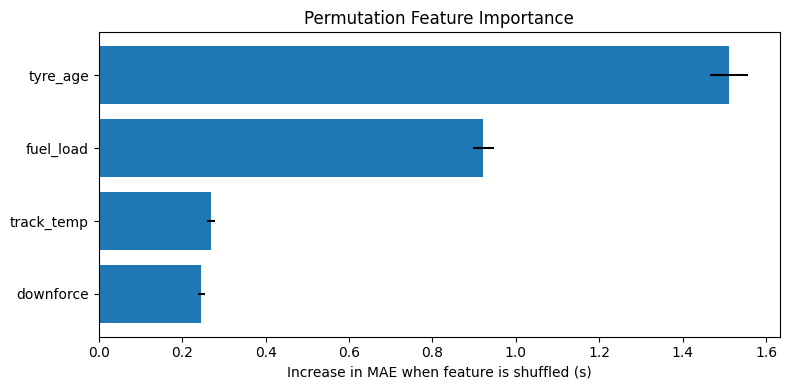

In [22]:

from sklearn.inspection import permutation_importance

importance = permutation_importance(
    polynomial_v2,
    X2_test,
    y2_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X2_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

print(importance_df.round(4))

plt.figure(figsize=(8, 4))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

plt.gca().invert_yaxis()
plt.xlabel("Increase in MAE when feature is shuffled (s)")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()
